In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('fake_news_data.csv')

In [3]:
data.head()

,title,text,date,fake_or_factual
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198 entries, 0 to 197
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   title            198 non-null    object
 1   text             198 non-null    object
 2   date             198 non-null    object
 3   fake_or_factual  198 non-null    object
dtypes: object(4)
memory usage: 6.3+ KB


In [5]:
plt.rcParams['figure.figsize'] = (14, 7)
default_plot_color = '#00bfbf'

Text(0, 0.5, 'Value counts')

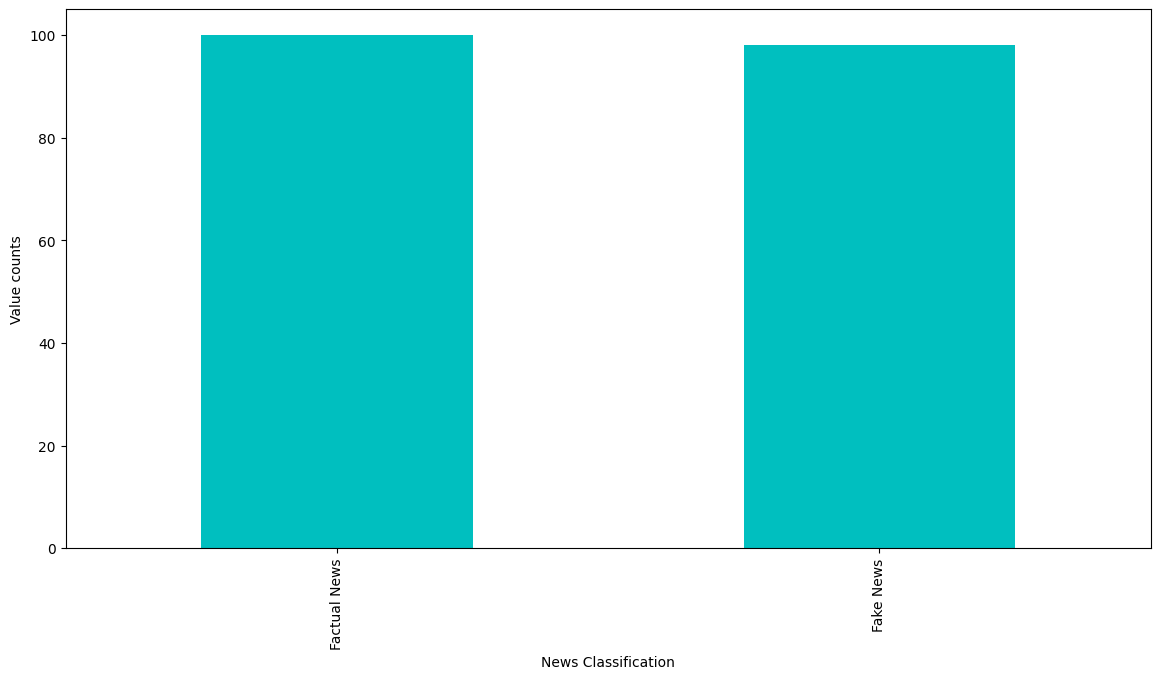

In [7]:
data['fake_or_factual'].value_counts().plot(kind='bar', color=default_plot_color)
plt.xlabel('News Classification')
plt.ylabel('Value counts')

In [13]:
import seaborn as sns
import spacy
from spacy import tokenizer
from spacy import displacy
import re
import nltk
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import accuracy_score, classification_report
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import gensim
import gensim.corpora as corpora
from gensim.models import LsiModel

In [14]:
fake_news = data[data['fake_or_factual'] == 'Fake News']

In [15]:
fact_news = data[data['fake_or_factual'] == 'Factual News']

In [16]:
nlp = spacy.load('en_core_web_sm')

In [17]:
fake_spacydocs = list(nlp.pipe(fake_news['text']))
fact_spacydocs = list(nlp.pipe(fact_news['text']))

In [18]:
def extract_token_tags(doc):
    return [(i.text, i.ent_type_, i.pos_) for i in doc]

In [20]:
fake_docdf = []
columns = ['text', 'ner_tags', 'pos_tags']
for ix, doc in enumerate(fake_spacydocs):
    tags = extract_token_tags(doc)
    tags = pd.DataFrame(tags)
    tags.columns=columns
    fake_docdf.append(tags)
fake_docdf = pd.concat(fake_docdf)

In [21]:
fact_docdf = []
columns = ['text', 'ner_tags', 'pos_tags']
for ix, doc in enumerate(fact_spacydocs):
    tags = extract_token_tags(doc)
    tags = pd.DataFrame(tags)
    tags.columns=columns
    fact_docdf.append(tags)
fact_docdf = pd.concat(fact_docdf)

In [22]:
fake_docdf.head()

,text,ner_tags,pos_tags
0,There,,PRON
1,are,,VERB
2,two,CARDINAL,NUM
3,small,,ADJ
4,problems,,NOUN


In [23]:
fact_docdf.head()

,text,ner_tags,pos_tags
0,WASHINGTON,GPE,PROPN
1,(,,PUNCT
2,Reuters,ORG,PROPN
3,),,PUNCT
4,-,,PUNCT


In [27]:
fake_counts = fake_docdf.groupby(['text', 'pos_tags']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
fake_counts.head(10)

,text,pos_tags,counts
29,",",PUNCT,1908
7451,the,DET,1834
41,.,PUNCT,1530
5766,of,ADP,922
2665,and,CCONJ,875
2449,a,DET,805
0,,SPACE,795
7528,to,PART,767
4921,in,ADP,668
5099,is,AUX,419


In [28]:
fact_counts = fact_docdf.groupby(['text', 'pos_tags']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
fact_counts.head(10)

,text,pos_tags,counts
6145,the,DET,1903
14,",",PUNCT,1698
21,.,PUNCT,1382
4716,of,ADP,884
1898,a,DET,789
2093,and,CCONJ,757
4005,in,ADP,671
6205,to,PART,660
4743,on,ADP,482
5567,said,VERB,451


In [30]:
fake_pos_tags = fake_docdf.groupby(['pos_tags'])['text'].count().sort_values(ascending=False)
fake_pos_tags.head(10)

pos_tags
NOUN     7799
PROPN    5337
VERB     5281
ADP      4533
PUNCT    4301
DET      3560
PRON     3119
ADJ      2710
AUX      2155
ADV      1672
Name: text, dtype: int64

In [31]:
fact_pos_tags = fact_docdf.groupby(['pos_tags'])['text'].count().sort_values(ascending=False)
fact_pos_tags.head(10)

pos_tags
NOUN     7288
PROPN    5187
VERB     4516
PUNCT    4436
ADP      4353
DET      3463
ADJ      2540
AUX      1838
PRON     1804
PART     1219
Name: text, dtype: int64

In [38]:
fake_counts[fake_counts.pos_tags == 'PRON'][0:15]

,text,pos_tags,counts
4776,his,PRON,240
4711,he,PRON,237
5108,it,PRON,224
7449,that,PRON,196
7925,who,PRON,195
7466,they,PRON,166
1133,I,PRON,164
8021,you,PRON,117
7453,their,PRON,114
4747,her,PRON,109


In [39]:
fact_counts[fact_counts.pos_tags == 'PROPN'][0:15]

,text,pos_tags,counts
1740,Trump,PROPN,229
1759,U.S.,PROPN,177
1472,Reuters,PROPN,131
1415,President,PROPN,89
907,House,PROPN,71
1777,United,PROPN,69
1319,Obama,PROPN,56
1637,States,PROPN,56
658,Donald,PROPN,50
1838,White,PROPN,48


In [42]:
fake_ner_tags = fake_docdf[fake_docdf['ner_tags'] != ""].groupby(['text', 'ner_tags']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
fake_ner_tags.head(10)                                                                                                                              

,text,ner_tags,counts
1730,Trump,PERSON,154
1729,Trump,ORG,152
2129,the,ORG,121
592,Clinton,PERSON,118
718,Donald,PERSON,75
890,Hillary,PERSON,64
1329,Obama,PERSON,59
1179,McCain,PERSON,53
2167,year,DATE,44
1662,Syria,GPE,42


In [43]:
fact_ner_tags = fact_docdf[fact_docdf['ner_tags'] != ''].groupby(['text', 'ner_tags']).size().reset_index(name='counts').sort_values(by='counts', ascending=False)
fact_ner_tags.head(10)

,text,ner_tags,counts
1968,the,ORG,159
1633,U.S.,GPE,138
1373,Reuters,ORG,131
1615,Trump,PERSON,125
1614,Trump,ORG,124
882,House,ORG,67
1997,year,DATE,63
1646,United,GPE,59
1965,the,GPE,59
1254,Obama,PERSON,55


In [46]:
ner_palette = {
    'ORG': sns.color_palette('Set2').as_hex()[0],
    'GPE': sns.color_palette('Set2').as_hex()[1],
    'PERSON': sns.color_palette('Set2').as_hex()[2],
    'DATE': sns.color_palette('Set2').as_hex()[3],
    'NORP': sns.color_palette('Set2').as_hex()[4],
    'CARDINAL': sns.color_palette('Set2').as_hex()[5],
    'PERCENT': sns.color_palette('Set2').as_hex()[6]
}

[Text(0.5, 1.0, 'NER TAGS')]

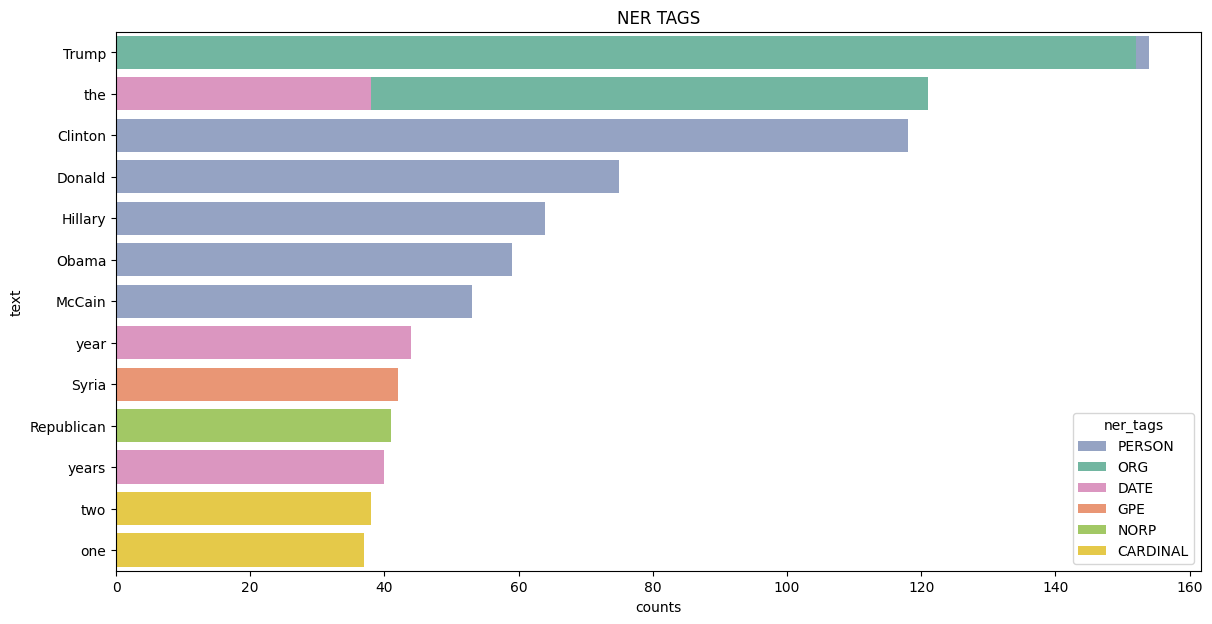

In [49]:
sns.barplot(x = 'counts', y = 'text', palette=ner_palette, hue='ner_tags', orient='h', data=fake_ner_tags[0:15], dodge=False).set(title= 'NER TAGS')

[Text(0.5, 1.0, 'NER TAGS')]

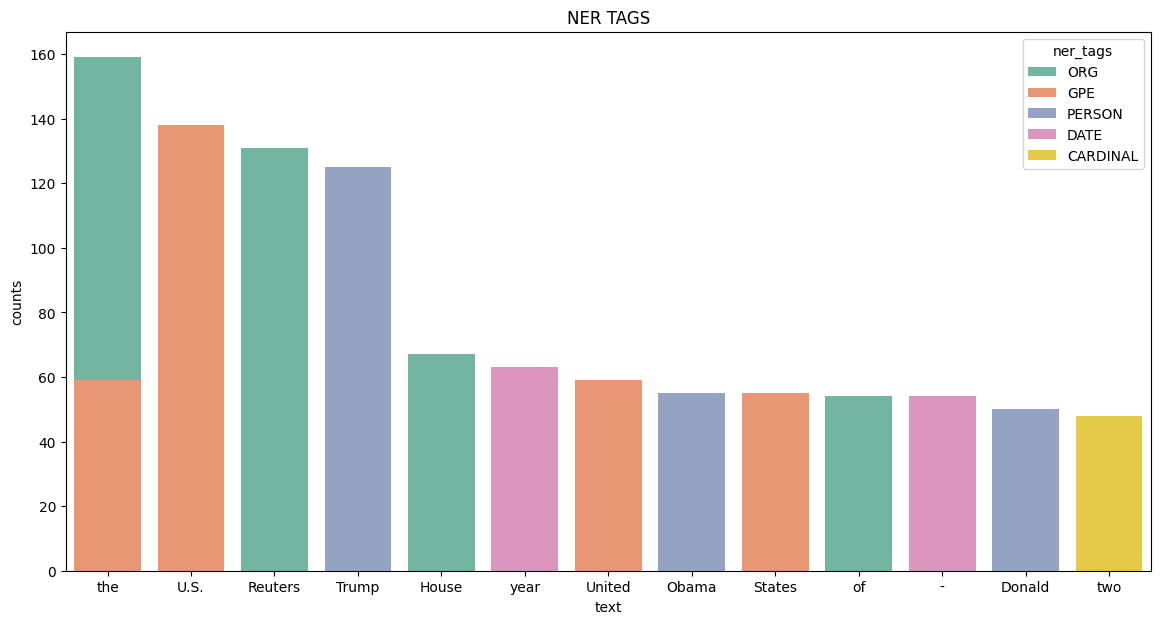

In [50]:
sns.barplot(x='text', y='counts', palette=ner_palette, orient='v', hue='ner_tags', dodge=False, data=fact_ner_tags[0:15]).set(title='NER TAGS')

In [66]:
data['text_clean'] = data.apply(lambda x: re.sub(r"^[^-]*-\s*", "", x['text']), axis=1)
data.head()

,title,text,date,fake_or_factual,cleaned_text,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,[yearoldoscarwinningactressdescribedmeeting16y...,year-old Oscar-winning actress described meeti...
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,[buriedtrumpbonkersinterviewnewyorktimesreport...,Buried in Trump s bonkers interview with New Y...
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,[womenmake50percentcountrygrosslyunderrepresen...,"Women make up over 50 percent of this country,..."
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,[usdefensesecretaryjimmattissaidmondayrussiabo...,U.S. Defense Secretary Jim Mattis said on Mond...
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,[northernirelandpoliticalpartiesrapidlyrunning...,Northern Ireland s political parties are rapid...


In [67]:
iiidata['text_clean'] = data['text_clean'].str.lower()
data.head()

,title,text,date,fake_or_factual,cleaned_text,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,[yearoldoscarwinningactressdescribedmeeting16y...,year-old oscar-winning actress described meeti...
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,[buriedtrumpbonkersinterviewnewyorktimesreport...,buried in trump s bonkers interview with new y...
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,[womenmake50percentcountrygrosslyunderrepresen...,"women make up over 50 percent of this country,..."
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,[usdefensesecretaryjimmattissaidmondayrussiabo...,u.s. defense secretary jim mattis said on mond...
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,[northernirelandpoliticalpartiesrapidlyrunning...,northern ireland s political parties are rapid...


In [68]:
data['text_clean'] = data.apply(lambda x: re.sub(r"([^\w\s])", "", x['text_clean']), axis=1)
data.head()

,title,text,date,fake_or_factual,cleaned_text,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,[yearoldoscarwinningactressdescribedmeeting16y...,yearold oscarwinning actress described meeting...
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,[buriedtrumpbonkersinterviewnewyorktimesreport...,buried in trump s bonkers interview with new y...
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,[womenmake50percentcountrygrosslyunderrepresen...,women make up over 50 percent of this country ...
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,[usdefensesecretaryjimmattissaidmondayrussiabo...,us defense secretary jim mattis said on monday...
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,[northernirelandpoliticalpartiesrapidlyrunning...,northern ireland s political parties are rapid...


In [56]:
en_stopwords = stopwords.words('english')

In [69]:
data['text_clean'] = data['text_clean'].apply(lambda x: ' '.join([word for word in x.split() if word not in (en_stopwords)]))
data.head()

,title,text,date,fake_or_factual,cleaned_text,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,[yearoldoscarwinningactressdescribedmeeting16y...,yearold oscarwinning actress described meeting...
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,[buriedtrumpbonkersinterviewnewyorktimesreport...,buried trump bonkers interview new york times ...
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,[womenmake50percentcountrygrosslyunderrepresen...,women make 50 percent country grossly underrep...
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,[usdefensesecretaryjimmattissaidmondayrussiabo...,us defense secretary jim mattis said monday ru...
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,[northernirelandpoliticalpartiesrapidlyrunning...,northern ireland political parties rapidly run...


In [70]:
data['text_clean'] = data.apply(lambda x: word_tokenize(x['text_clean']), axis=1)
data.head()

,title,text,date,fake_or_factual,cleaned_text,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,[yearoldoscarwinningactressdescribedmeeting16y...,"[yearold, oscarwinning, actress, described, me..."
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,[buriedtrumpbonkersinterviewnewyorktimesreport...,"[buried, trump, bonkers, interview, new, york,..."
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,[womenmake50percentcountrygrosslyunderrepresen...,"[women, make, 50, percent, country, grossly, u..."
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,[usdefensesecretaryjimmattissaidmondayrussiabo...,"[us, defense, secretary, jim, mattis, said, mo..."
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,[northernirelandpoliticalpartiesrapidlyrunning...,"[northern, ireland, political, parties, rapidl..."


In [73]:
lemmatizer = WordNetLemmatizer()
data['text_clean'] = data['text_clean'].apply(lambda x: [lemmatizer.lemmatize(token) for token in x])
data.head()

,title,text,date,fake_or_factual,cleaned_text,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,[yearoldoscarwinningactressdescribedmeeting16y...,"[yearold, oscarwinning, actress, described, me..."
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,[buriedtrumpbonkersinterviewnewyorktimesreport...,"[buried, trump, bonkers, interview, new, york,..."
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,[womenmake50percentcountrygrosslyunderrepresen...,"[woman, make, 50, percent, country, grossly, u..."
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,[usdefensesecretaryjimmattissaidmondayrussiabo...,"[u, defense, secretary, jim, mattis, said, mon..."
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,[northernirelandpoliticalpartiesrapidlyrunning...,"[northern, ireland, political, party, rapidly,..."


In [80]:
data.head()

,title,text,date,fake_or_factual,text_clean
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,"[yearold, oscarwinning, actress, described, me..."
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,"[buried, trump, bonkers, interview, new, york,..."
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,"[woman, make, 50, percent, country, grossly, u..."
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,"[u, defense, secretary, jim, mattis, said, mon..."
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,"[northern, ireland, political, party, rapidly,..."


In [89]:
cleaned_tokens = sum(data['text_clean'], [])
fourgrams = pd.Series(nltk.ngrams(cleaned_tokens, 4)).value_counts().reset_index()[0:15]
print(fourgrams)

                                     index  count
0            (u, president, donald, trump)     10
1            (fbi, director, james, comey)      6
2       (secretary, state, rex, tillerson)      5
3           (white, house, official, said)      5
4           (former, fbi, director, james)      5
5   (otherwise, lovable, rascalsjoin, acr)      4
6               (u, secretary, state, rex)      4
7   (speaking, condition, anonymity, said)      4
8      (japanese, prime, minister, shinzo)      4
9                    (wa, lone, kyaw, soe)      4
10          (prime, minister, shinzo, abe)      4
11                   (lone, kyaw, soe, oo)      4
12            (host, hesher, spore, along)      4
13              (acr, host, hesher, spore)      4
14        (rascalsjoin, acr, host, hesher)      4


C:\Users\Rudra\AppData\Local\Temp\ipykernel_36316\1561805078.py:2: UserWarning: 
The palette list has fewer values (1) than needed (15) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x = 'count', y= 'tokens', orient='h', hue='tokens', palette=[default_plot_color], data=fourgrams, legend=False).set(title='N-GRAMS')


[Text(0.5, 1.0, 'N-GRAMS')]

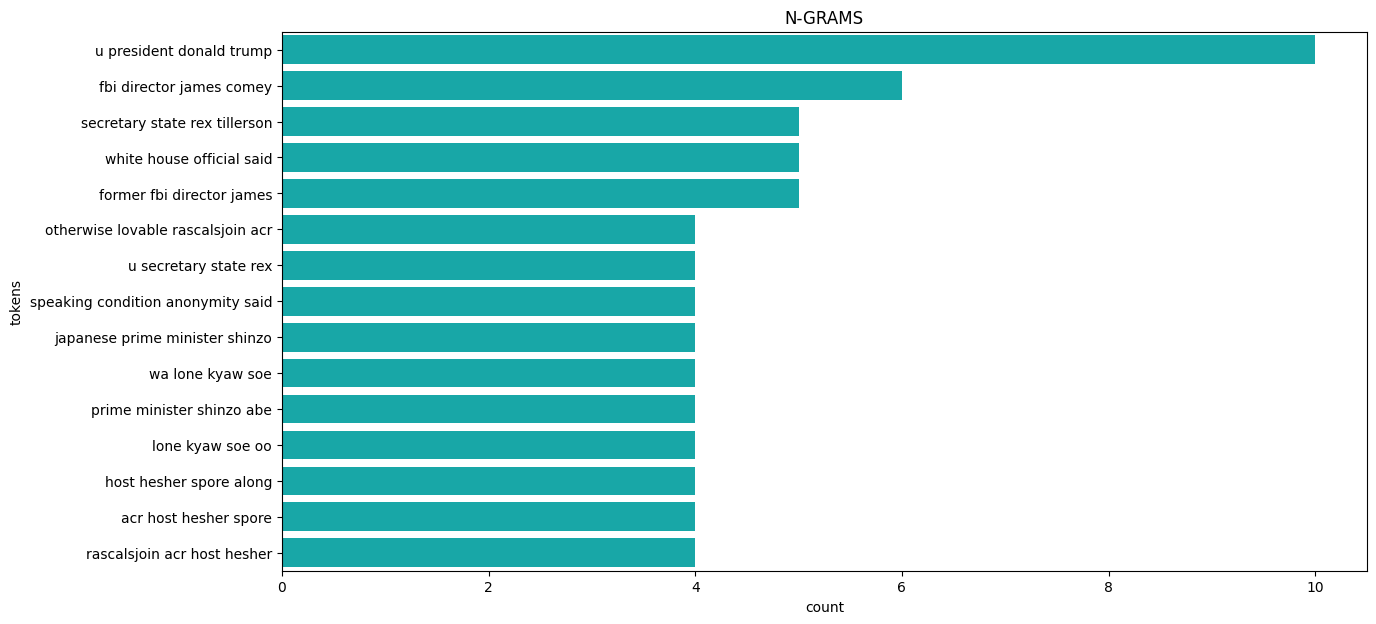

In [90]:
fourgrams['tokens'] = fourgrams['index'].apply(lambda x: ' '.join(x))
sns.barplot(x = 'count', y= 'tokens', orient='h', hue='tokens', palette=[default_plot_color], data=fourgrams, legend=False).set(title='N-GRAMS')

In [92]:
sent = SentimentIntensityAnalyzer()
data['sentiment'] = data['text'].apply(lambda x: sent.polarity_scores(x)['compound'])
data.head()

,title,text,date,fake_or_factual,text_clean,sentiment
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,"[yearold, oscarwinning, actress, described, me...",-0.3660
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,"[buried, trump, bonkers, interview, new, york,...",-0.8197
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,"[woman, make, 50, percent, country, grossly, u...",0.9779
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,"[u, defense, secretary, jim, mattis, said, mon...",-0.3400
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,"[northern, ireland, political, party, rapidly,...",0.8590


<Axes: xlabel='sent_label'>

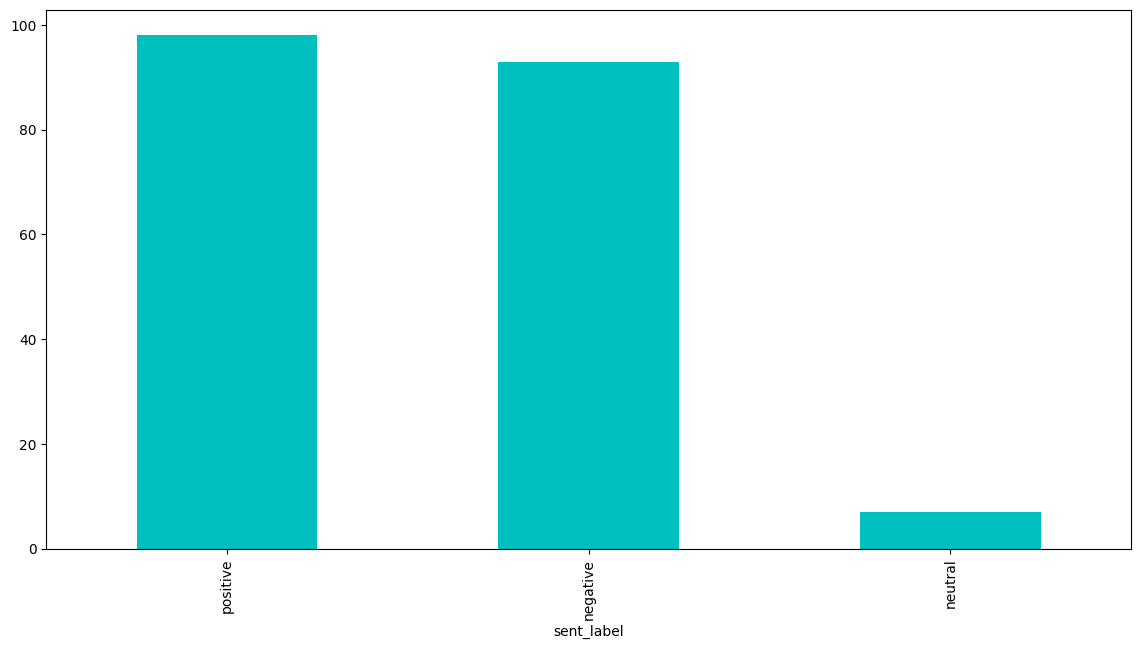

In [94]:
bins = [-1, -0.1, 0.1, 1]
labels = ['negative', 'neutral', 'positive']
data['sent_label'] = pd.cut(data['sentiment'], bins, labels=labels)
data['sent_label'].value_counts().plot.bar(color=default_plot_color)

C:\Users\Rudra\AppData\Local\Temp\ipykernel_36316\1161165961.py:1: UserWarning: The palette list has more values (6) than needed (3), which may not be intended.
  sns.countplot(x='fake_or_factual', hue='sent_label', data=data, orient='v', palette=sns.color_palette('hls'))


<Axes: xlabel='fake_or_factual', ylabel='count'>

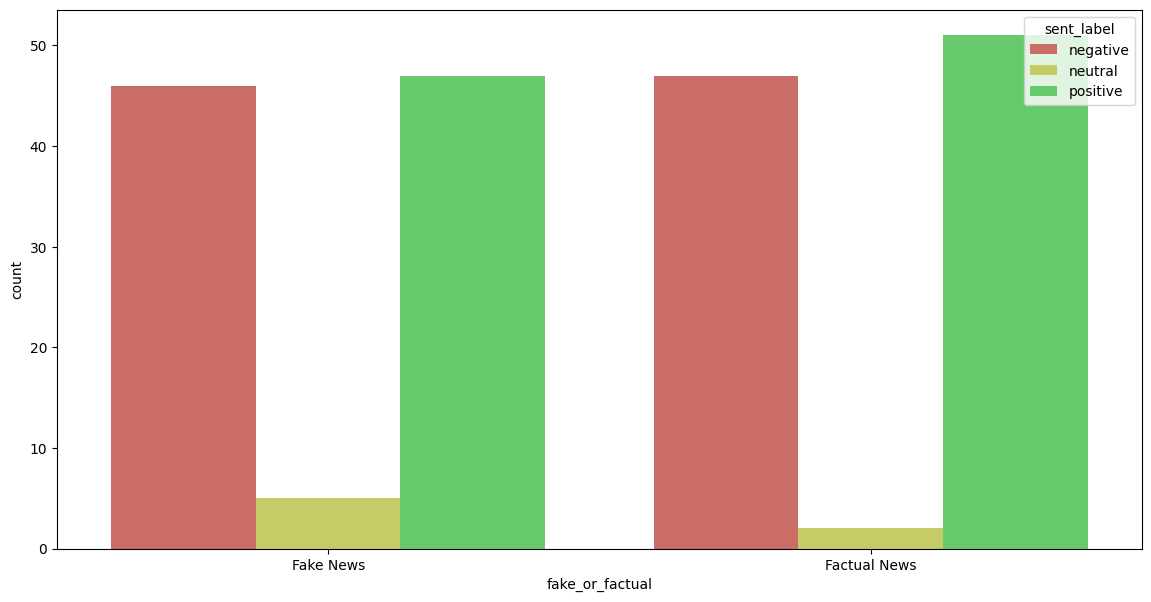

In [97]:
sns.countplot(x='fake_or_factual', hue='sent_label', data=data, orient='v', palette=sns.color_palette('hls'))

In [99]:
from gensim.models.coherencemodel import CoherenceModel
from gensim.models import TfidfModel 

In [100]:
fake_news_text = data[data['fake_or_factual'] == 'Fake News']['text_clean'].reset_index(drop=True)

In [101]:
fake_dict = corpora.Dictionary(fake_news_text)
fake_doc_term = [fake_dict.doc2bow(text) for text in fake_news_text]

In [105]:
models_list=[]
coherence_values=[]
min_v =2 
max_v = 12
for numtopics_i in range(min_v, max_v+1):
    model = gensim.models.LdaModel(fake_doc_term, num_topics=numtopics_i, id2word=fake_dict)
    models_list.append(model)
    coherence_model = CoherenceModel(model=model, texts=fake_news_text,dictionary=fake_dict, coherence='c_v')
    coherence_values.append(coherence_model.get_coherence())

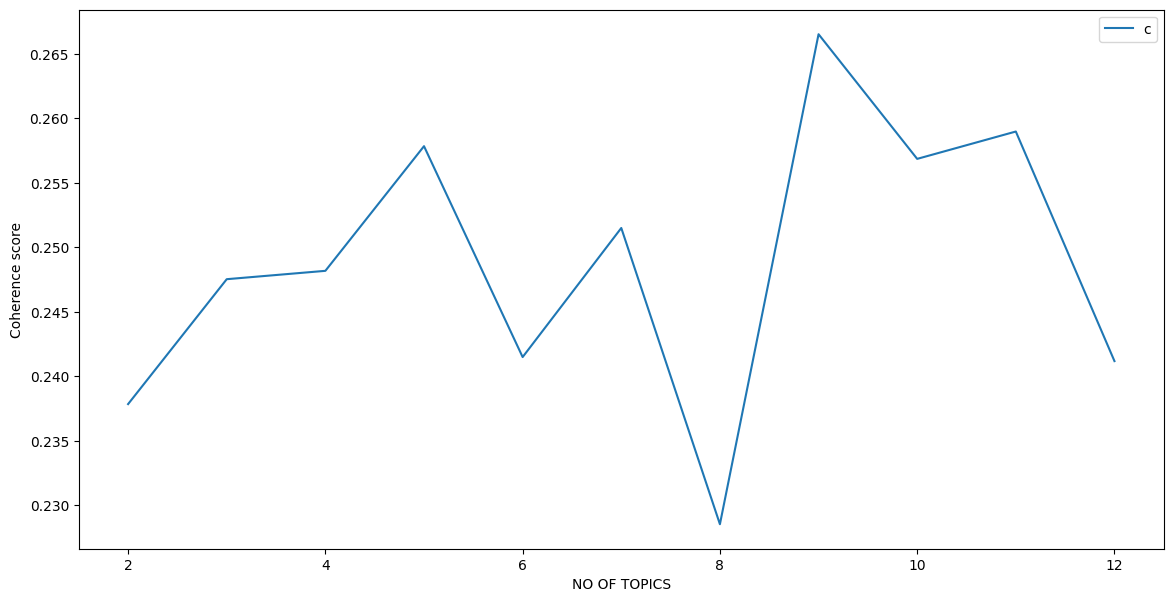

In [106]:
plt.plot(range(min_v, max_v+1), coherence_values)
plt.xlabel('NO OF TOPICS')
plt.ylabel('Coherence score')
plt.legend(('coherence_values'), loc='best')
plt.show()

In [109]:
fake_num_topics = 9
lda_model = gensim.models.LdaModel(corpus=fake_doc_term, id2word=fake_dict, num_topics=fake_num_topics)
lda_model.print_topics(num_topics=fake_num_topics, num_words=10)

[(0,
  '0.008*"trump" + 0.005*"would" + 0.004*"president" + 0.003*"one" + 0.003*"said" + 0.003*"u" + 0.003*"new" + 0.003*"year" + 0.003*"also" + 0.002*"want"'),
 (1,
  '0.009*"said" + 0.006*"state" + 0.005*"trump" + 0.005*"student" + 0.004*"one" + 0.004*"president" + 0.004*"u" + 0.003*"time" + 0.003*"could" + 0.003*"worker"'),
 (2,
  '0.008*"trump" + 0.004*"mccain" + 0.003*"time" + 0.003*"u" + 0.003*"one" + 0.003*"president" + 0.003*"syria" + 0.003*"said" + 0.003*"people" + 0.002*"clinton"'),
 (3,
  '0.023*"trump" + 0.005*"president" + 0.005*"state" + 0.005*"would" + 0.004*"time" + 0.004*"said" + 0.004*"clinton" + 0.004*"one" + 0.003*"school" + 0.003*"donald"'),
 (4,
  '0.010*"trump" + 0.004*"clinton" + 0.004*"said" + 0.004*"president" + 0.004*"republican" + 0.003*"u" + 0.003*"time" + 0.003*"one" + 0.003*"new" + 0.003*"mccain"'),
 (5,
  '0.009*"trump" + 0.006*"clinton" + 0.004*"republican" + 0.004*"hillary" + 0.003*"said" + 0.003*"one" + 0.003*"people" + 0.003*"room" + 0.003*"made" + 0

In [113]:
def tfidf_matrix(doc_term):
    tfidf_model = TfidfModel(corpus=doc_term, normalize=True)
    fake_tf_idf_matrix = tfidf_model[doc_term]
    return fake_tf_idf_matrix
    

In [117]:
def get_coherence_score(corpus, dictionary, text, min_v, max_v):
    coherence_values = []
    models_list = []
    for num_topicsi in range(min_v, max_v+1):
        model = LsiModel(fake_doc_term, id2word=dictionary, num_topics=num_topicsi)
        models_list.append(model)
        coherence_model = CoherenceModel(model=model, dictionary=dictionary, texts=text, coherence = 'c_v')
        coherence_values.append(coherence_model.get_coherence())
    plt.plot(range(min_v, max_v+1), coherence_values)
    plt.xlabel('No. of topics')
    plt.ylabel('Coherence scores')
    plt.legend(('coherence_values'), loc='best')
    plt.show()

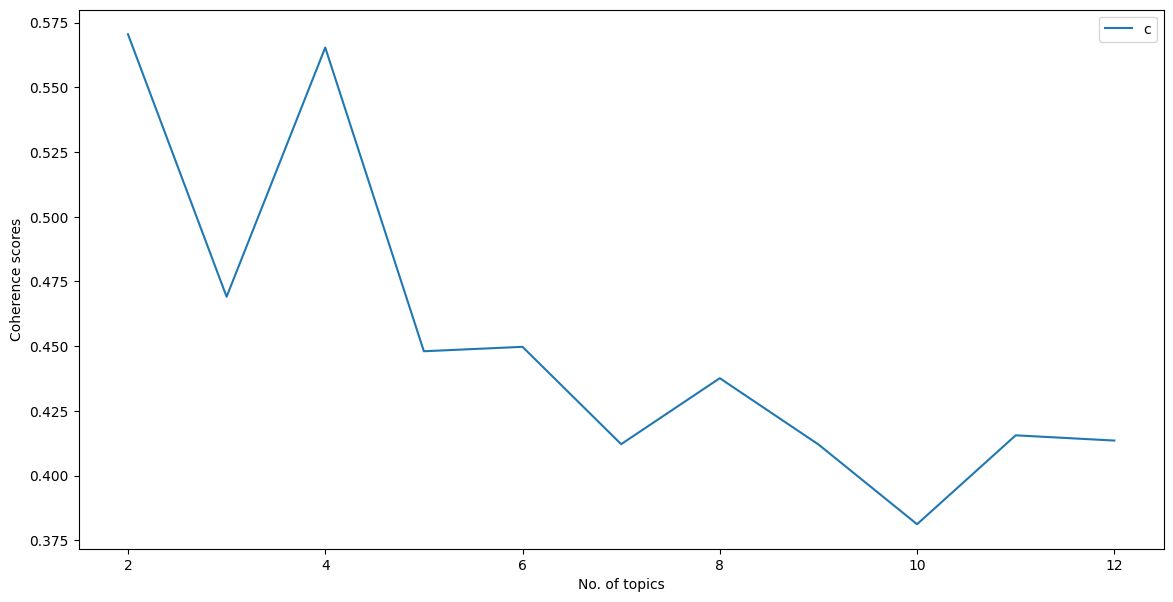

In [118]:
fake_corpus = tfidf_matrix(fake_doc_term)
get_coherence_score(fake_corpus, fake_dict, fake_news_text, 2, 12)

In [120]:
lsi_model = LsiModel(fake_corpus, id2word=fake_dict, num_topics=4)
lsi_model.print_topics()

[(0,
  '0.218*"trump" + 0.135*"clinton" + 0.094*"woman" + 0.087*"president" + 0.086*"republican" + 0.085*"obama" + 0.084*"party" + 0.083*"school" + 0.081*"said" + 0.079*"time"'),
 (1,
  '-0.299*"boiler" + -0.253*"room" + -0.250*"acr" + -0.186*"jay" + -0.185*"animal" + -0.176*"episode" + -0.147*"analysis" + -0.122*"dyer" + -0.119*"moralist" + -0.119*"savant"'),
 (2,
  '-0.219*"school" + 0.195*"clinton" + 0.163*"conference" + -0.151*"county" + -0.137*"student" + 0.120*"press" + 0.116*"trump" + 0.112*"hillary" + -0.101*"love" + 0.095*"email"'),
 (3,
  '0.375*"flynn" + 0.151*"russian" + 0.111*"email" + 0.109*"30" + 0.101*"department" + 0.100*"information" + 0.100*"nana" + 0.099*"official" + 0.098*"mccain" + -0.096*"trump"')]

In [121]:
data.head()

,title,text,date,fake_or_factual,text_clean,sentiment,sent_label
0,HOLLYWEIRD LIB SUSAN SARANDON Compares Muslim ...,There are two small problems with your analogy...,"Dec 30, 2015",Fake News,"[yearold, oscarwinning, actress, described, me...",-0.3660,negative
1,Elijah Cummings Called Trump Out To His Face ...,Buried in Trump s bonkers interview with New Y...,"April 6, 2017",Fake News,"[buried, trump, bonkers, interview, new, york,...",-0.8197,negative
2,Hillary Clinton Says Half Her Cabinet Will Be...,"Women make up over 50 percent of this country,...","April 26, 2016",Fake News,"[woman, make, 50, percent, country, grossly, u...",0.9779,positive
3,Russian bombing of U.S.-backed forces being di...,WASHINGTON (Reuters) - U.S. Defense Secretary ...,"September 18, 2017",Factual News,"[u, defense, secretary, jim, mattis, said, mon...",-0.3400,negative
4,Britain says window to restore Northern Irelan...,BELFAST (Reuters) - Northern Ireland s politic...,"September 4, 2017",Factual News,"[northern, ireland, political, party, rapidly,...",0.8590,positive


In [122]:
X = [', '.join(map(str, l)) for l in data['text_clean']]
Y = data['fake_or_factual']

In [124]:
countvec = CountVectorizer()
countvec_fit = countvec.fit_transform(X)
bog = pd.DataFrame(countvec_fit.toarray(), columns=countvec.get_feature_names_out())

In [125]:
X_train, X_test, Y_train, Y_test = train_test_split(bog, Y, test_size=0.3)

In [126]:
lr = LogisticRegression(random_state=0).fit(X_train, Y_train)

In [127]:
lr_prediction = lr.predict(X_test)

In [128]:
accuracy_score(lr_prediction, Y_test)

0.85

In [129]:
svm = SGDClassifier().fit(X_train, Y_train)
svm_prediction = svm.predict(X_test)

In [130]:
accuracy_score(svm_prediction, Y_test)

0.8333333333333334